### L

In [60]:
from neo_ls_svm import NeoLSSVM as LSSVM
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.multioutput import MultiOutputRegressor

In [61]:
wkdir = r"C:/Users/agbob/OSUCLAB/ADD/FOSSE/osuc_digital_twin/"
data_dir = wkdir + "data/"

file_name = "data_combi_interpolee.csv"

path = os.path.join(data_dir, file_name)

In [62]:
data = pd.read_csv(path, sep=';')
data.head()

,date,temperature_om,humidity_om,pressure_om,wind_speed_om,wind_direction_om,precipitation_om,soil_temperature_6cm_om,soil_temperature_18cm_om,soil_temperature_54cm_om,...,c_sonde2,pH_sonde2,T_sonde3,H_sonde3,c_sonde3,pH_sonde3,T_sonde4,H_sonde4,c_sonde4,pH_sonde4
0,13/10/2025 00:00,9.3805,94.0,1026.199951,10.514218,51.952908,0.0,11.080501,13.980500,14.580501,...,0.0,7.98,14.1,17.18,0.0,9.0,12.9,16.0,0.0,6.9
1,13/10/2025 01:00,8.9805,94.0,1025.900024,11.019764,51.632477,0.0,10.830501,13.730500,14.580501,...,0.0,7.98,14.1,17.18,0.0,9.0,12.9,16.0,0.0,6.9
2,13/10/2025 02:00,8.6805,95.0,1025.699951,10.990322,58.392544,0.0,10.530500,13.530500,14.580501,...,0.0,7.98,14.1,17.18,0.0,9.0,12.9,16.0,0.0,6.9
3,13/10/2025 03:00,8.2805,95.0,1024.900024,11.090103,54.246033,0.0,10.230500,13.280500,14.530500,...,0.0,7.98,14.1,17.18,0.0,9.0,12.9,16.0,0.0,6.9
4,13/10/2025 04:00,7.9305,95.0,1025.099976,11.246759,50.194473,0.0,9.980500,13.080501,14.530500,...,0.0,7.98,14.1,17.18,0.0,9.0,12.9,16.0,0.0,6.9


In [63]:
data["date"] = pd.to_datetime(data["date"], format="%d/%m/%Y %H:%M")
data.set_index("date", inplace=True)

In [64]:
x_cols = [
    'temperature_om', 'humidity_om', 'pressure_om', 'wind_speed_om',
    'wind_direction_om', 'precipitation_om', 'soil_temperature_6cm_om',
    'soil_temperature_18cm_om', 'soil_temperature_54cm_om',
    'solarRadiation', 'winddir', 'humidity', 'metric_temp',
    'metric_windSpeed', 'metric_windGust', 'metric_pressure',
    'metric_precipRate', 'metric_precipTotal'
]

y_cols = [
    'T_sonde1', 'H_sonde1', 'pH_sonde1', 
    'T_sonde2', 'H_sonde2', 'pH_sonde2',
    'T_sonde3', 'H_sonde3', 'pH_sonde3',
    'T_sonde4', 'H_sonde4', 'pH_sonde4'
]

X = data[x_cols].values
Y = data[y_cols].values

In [65]:
X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)
Y_train, Y_test = train_test_split(Y, test_size=0.2, random_state=42)

In [66]:
model = LSSVM()
model = MultiOutputRegressor(model)
model.fit(X_train, Y_train)
Y_pred = model.predict(X_test)

In [67]:
print("Mean Squared Error:", mean_squared_error(Y_test, Y_pred))
print("R^2 Score:", r2_score(Y_test, Y_pred))

Mean Squared Error: 0.11529243034570165
R^2 Score: 0.7964704435603839


Text(0.5, 1.0, 'Actual vs Predicted for T_sonde1 and H_sonde1')

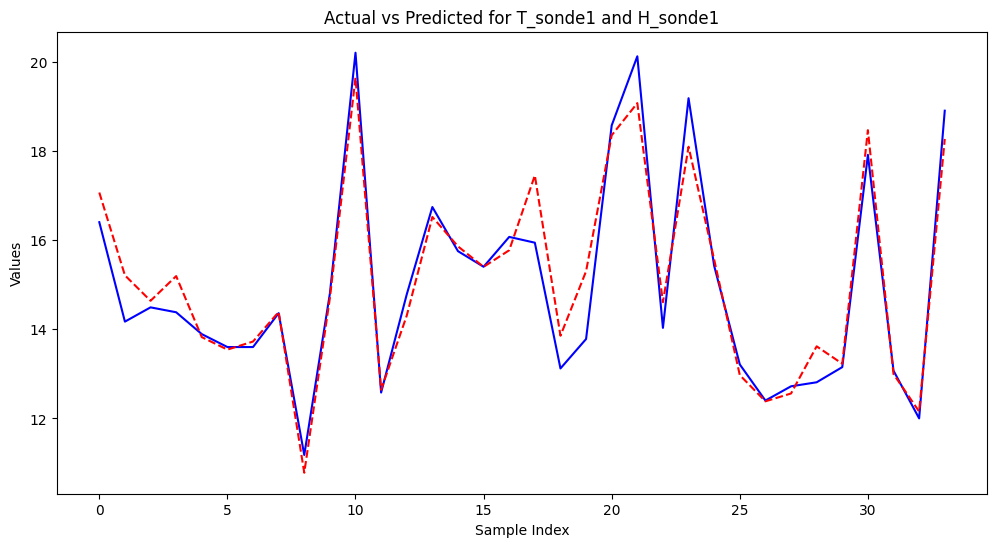

In [68]:
# show predicted vs actual for first output variable in time
plt.figure(figsize=(12, 6))
plt.plot(Y_test[:, 0], label='Actual T_sonde1', color='blue')
plt.plot(Y_pred[:, 0], label='Predicted T_sonde1', color='red', linestyle='--')
plt.xlabel('Sample Index')
plt.ylabel('Values')
plt.title('Actual vs Predicted for T_sonde1 and H_sonde1')

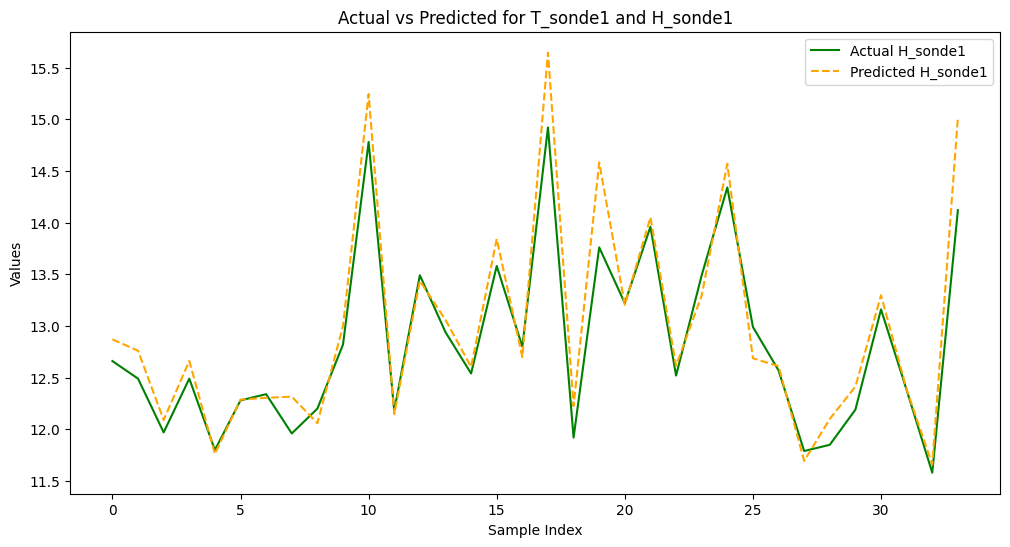

In [69]:
# show humidity
plt.figure(figsize=(12, 6))
plt.plot(Y_test[:, 1], label='Actual H_sonde1', color='green')
plt.plot(Y_pred[:, 1], label='Predicted H_sonde1', color='orange', linestyle='--')
plt.xlabel('Sample Index')
plt.ylabel('Values')
plt.title('Actual vs Predicted for T_sonde1 and H_sonde1')
plt.legend()
plt.show()

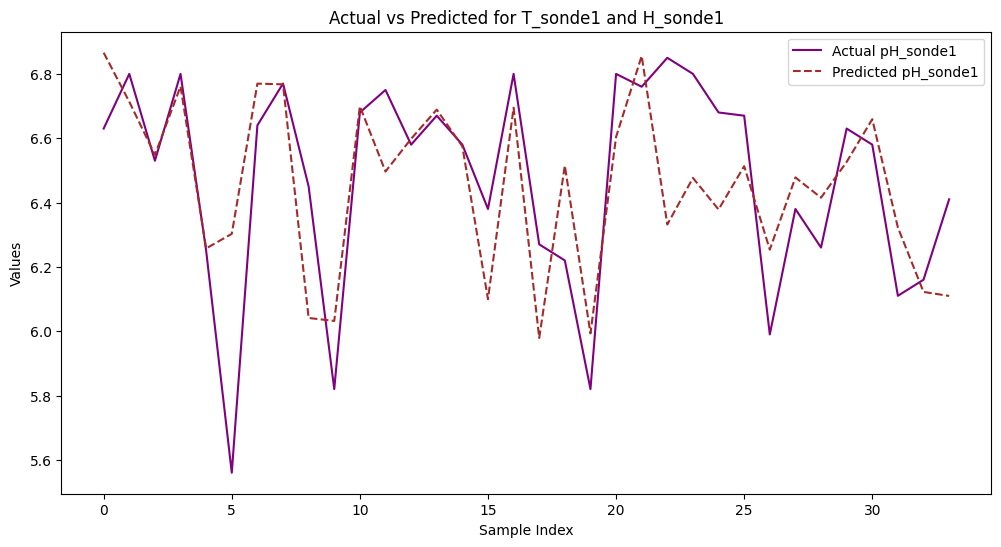

In [70]:
# show pH 
plt.figure(figsize=(12, 6))
plt.plot(Y_test[:, 2], label='Actual pH_sonde1', color='purple')
plt.plot(Y_pred[:, 2], label='Predicted pH_sonde1', color='brown', linestyle='--')
plt.xlabel('Sample Index')  
plt.ylabel('Values')
plt.title('Actual vs Predicted for T_sonde1 and H_sonde1')
plt.legend()
plt.show()

Output Variable 1: RMSE = 0.6032, MAE = 0.4327


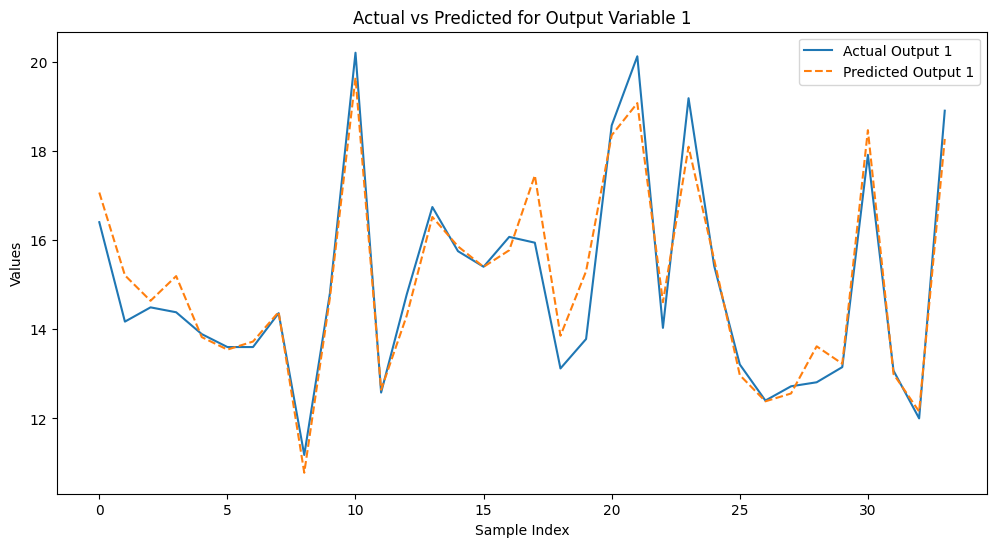

Output Variable 2: RMSE = 0.3020, MAE = 0.2098


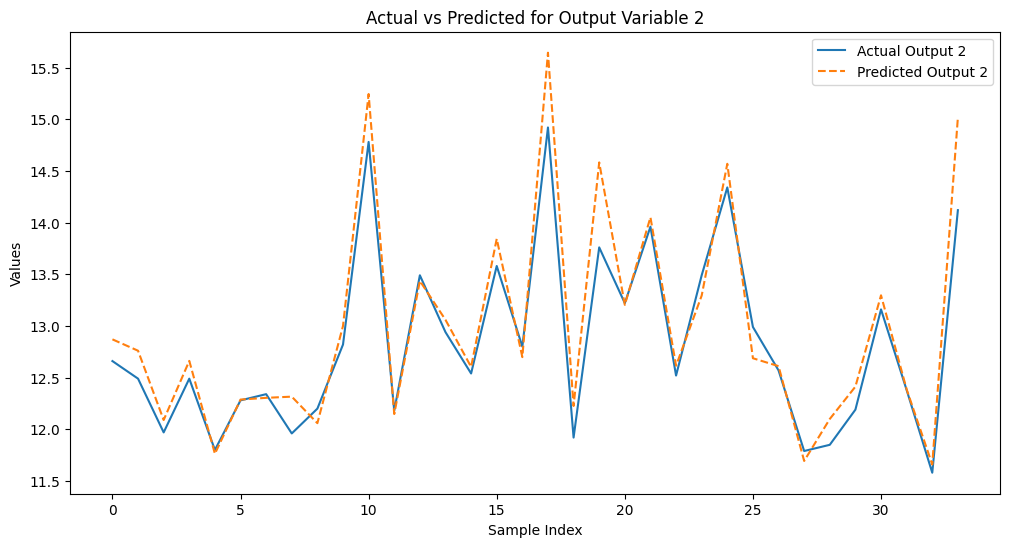

Output Variable 3: RMSE = 0.2423, MAE = 0.1819


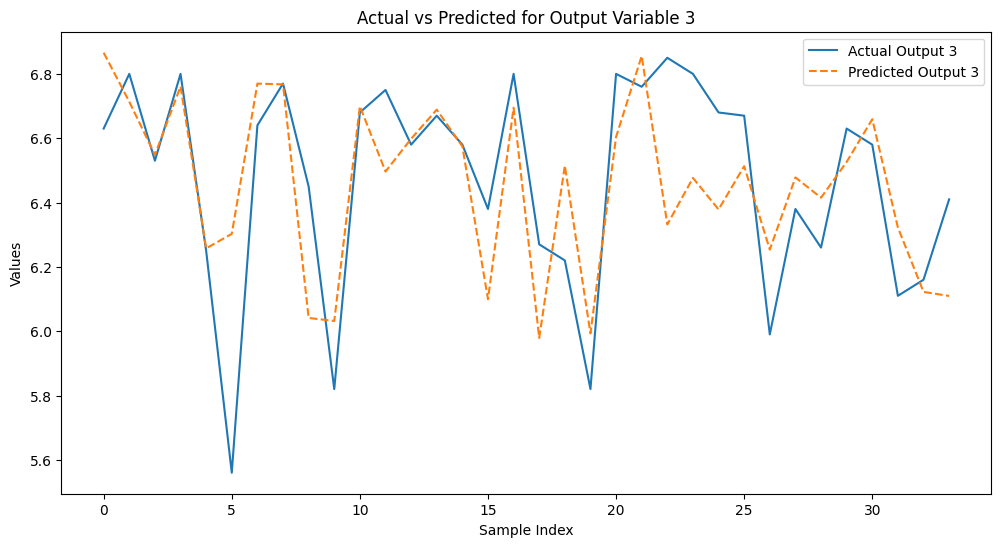

Output Variable 4: RMSE = 0.6159, MAE = 0.4696


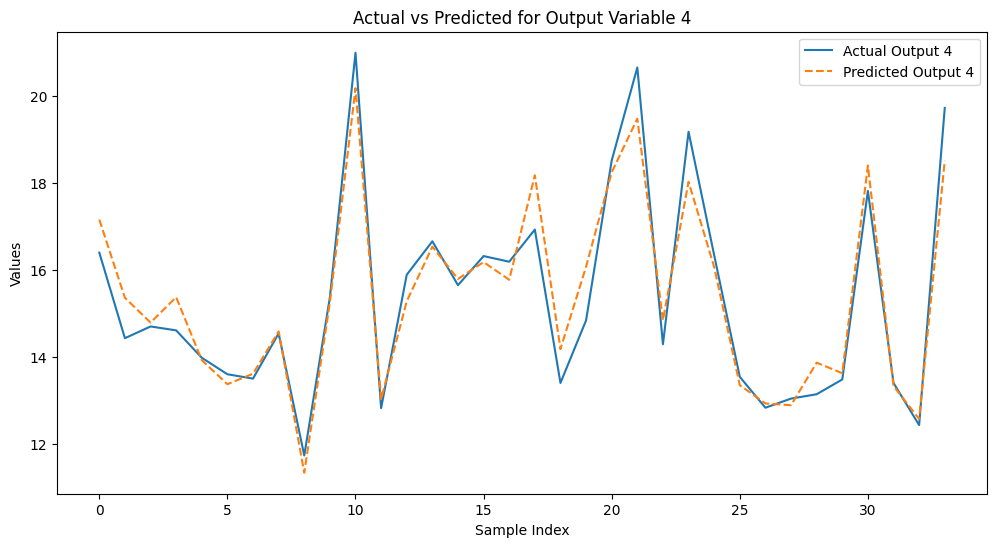

Output Variable 5: RMSE = 0.0686, MAE = 0.0533


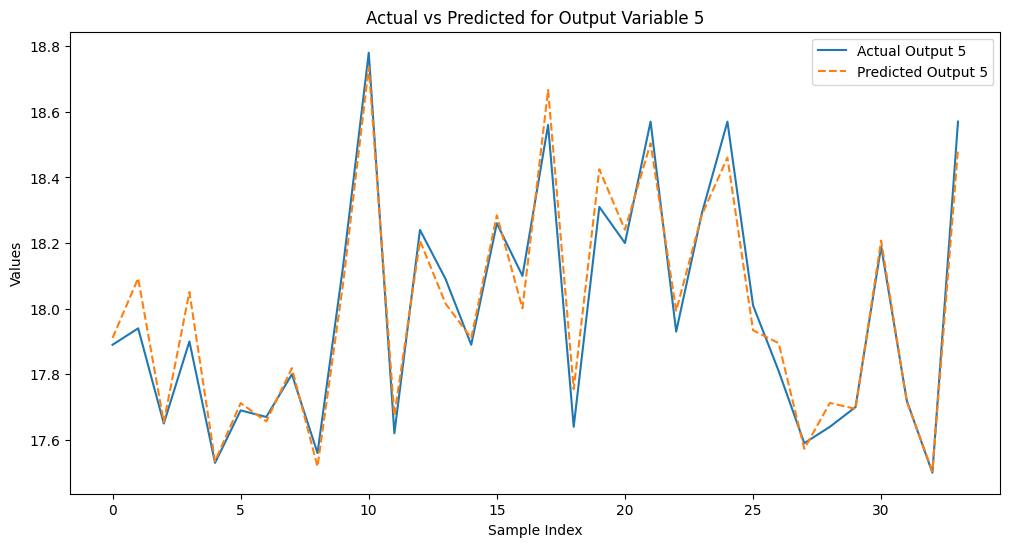

Output Variable 6: RMSE = 0.2660, MAE = 0.2099


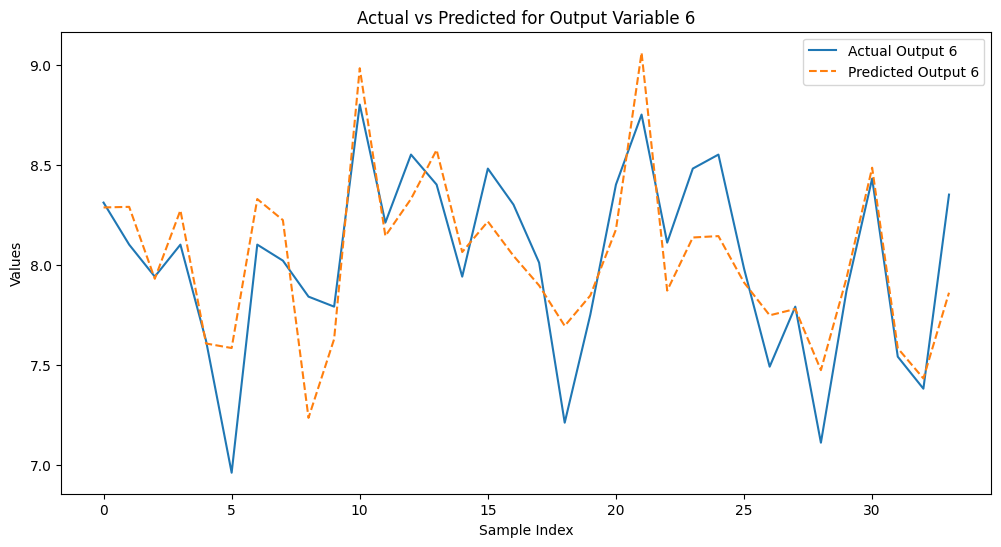

Output Variable 7: RMSE = 0.4117, MAE = 0.3118


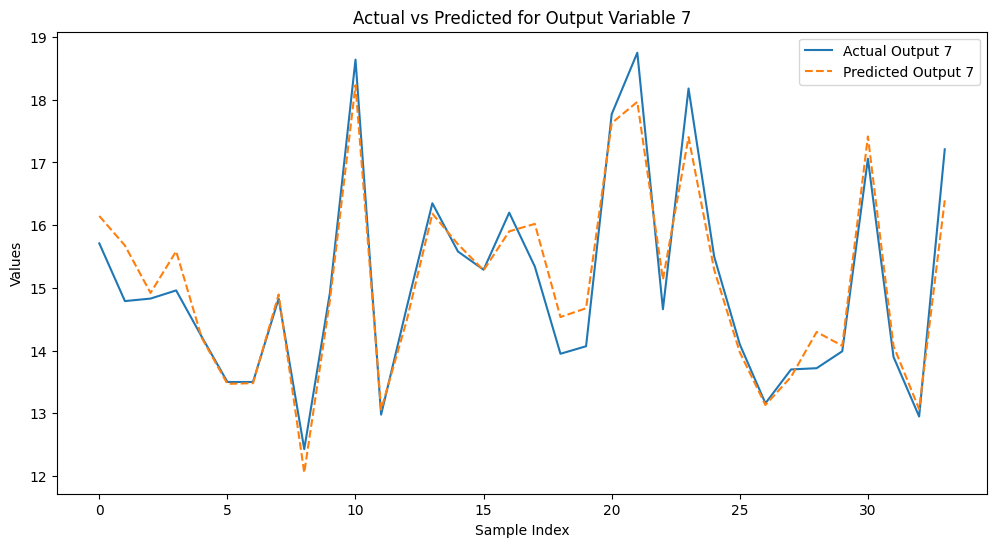

Output Variable 8: RMSE = 0.0667, MAE = 0.0534


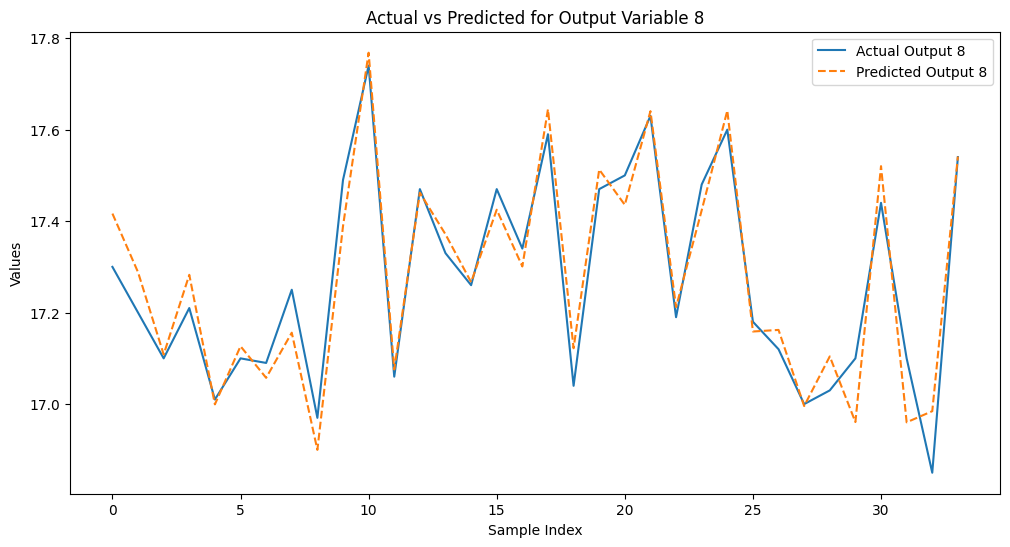

Output Variable 9: RMSE = 0.2238, MAE = 0.1704


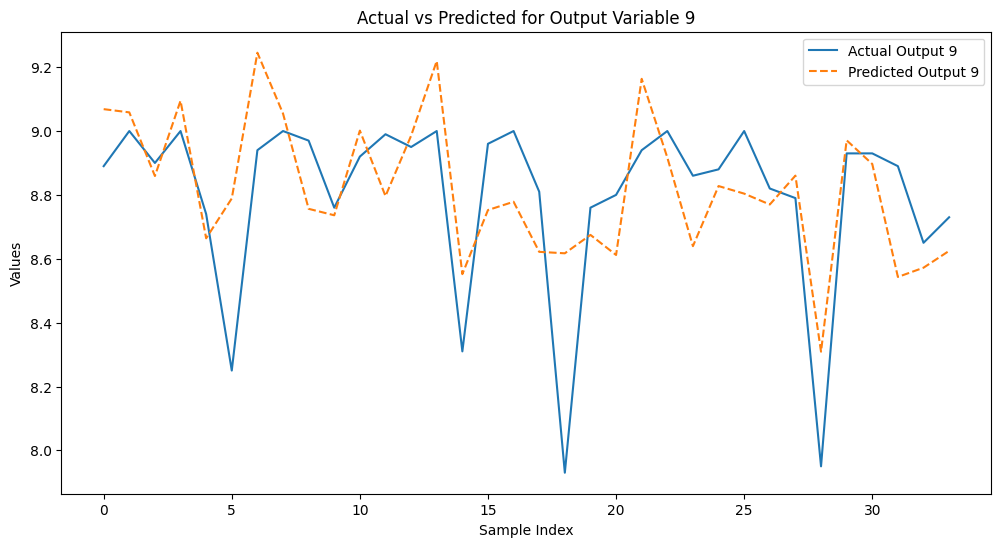

Output Variable 10: RMSE = 0.3307, MAE = 0.2519


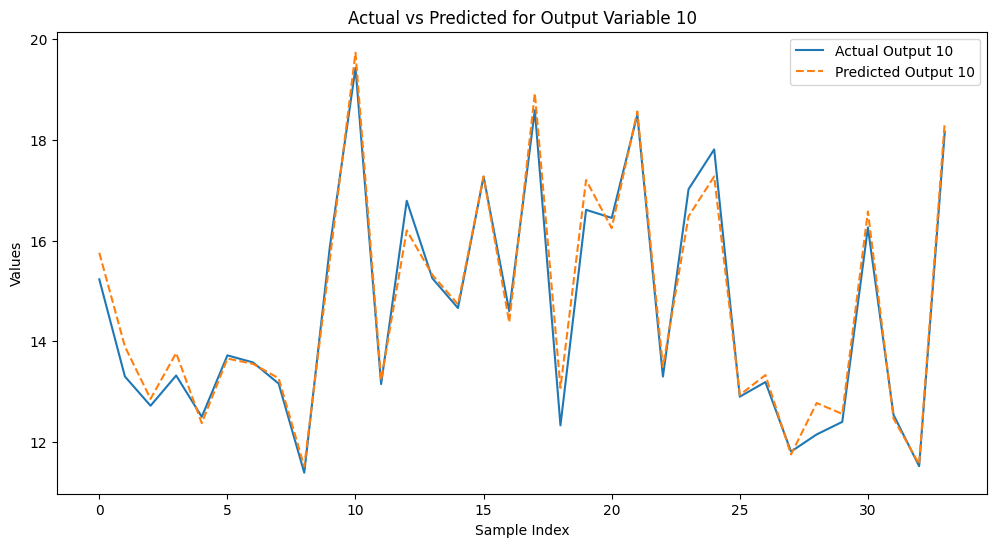

Output Variable 11: RMSE = 0.1402, MAE = 0.1079


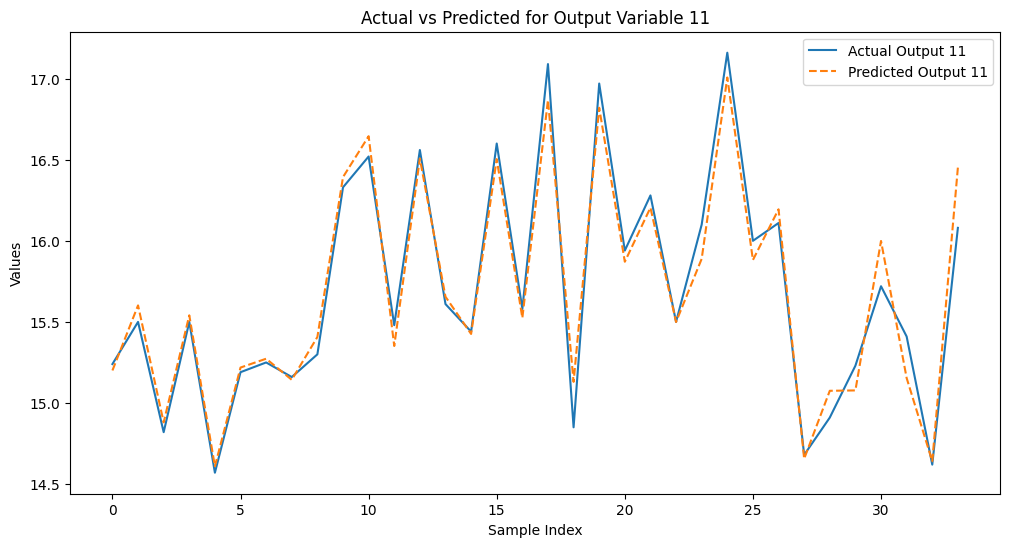

Output Variable 12: RMSE = 0.2489, MAE = 0.1869


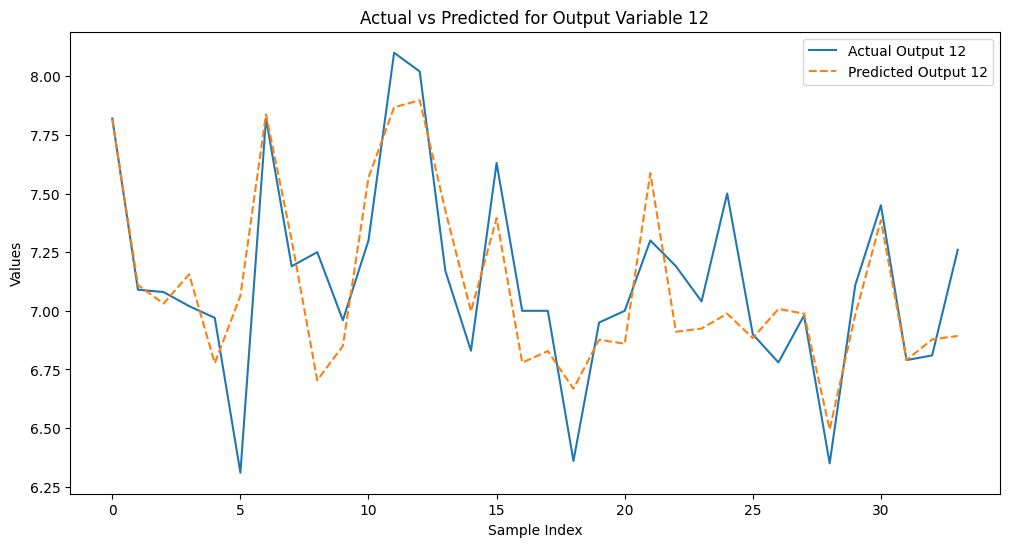

In [71]:
# Compute RMSE and MAE for each output variable
rmse = np.sqrt(mean_squared_error(Y_test, Y_pred, multioutput='raw_values'))
mae = np.mean(np.abs(Y_test - Y_pred), axis=0)  
for i in range(Y.shape[1]):
    print(f"Output Variable {i+1}: RMSE = {rmse[i]:.4f}, MAE = {mae[i]:.4f}")
    plt.figure(figsize=(12, 6))
    plt.plot(Y_test[:, i], label=f'Actual Output {i+1}')
    plt.plot(Y_pred[:, i], label=f'Predicted Output {i+1}', linestyle='--')
    plt.xlabel('Sample Index')
    plt.ylabel('Values')
    plt.title(f'Actual vs Predicted for Output Variable {i+1}')
    plt.legend()
    plt.show()
